In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# YOLOv11 설치
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 41.4 MB/s eta 0:00:00


In [8]:
import os
os.getcwd()

'/content'

In [15]:
# 여기 수정해야 함 + 각자 본인한테 맞는 경로로 수정해야 함
PLANT_NAME = '금전수'

In [16]:
# ============================================================
# 0) 설치 (Colab에서만 필요)
# ============================================================
# !pip -q install ultralytics
# !pip -q install tensorflow

import os
import cv2
import numpy as np
from ultralytics import YOLO
import tensorflow as tf


# ============================================================
# 1) 사용자 설정: 모델 경로 & 옵션  -> 각자 본인한테 맞는 경로로 수정해야 함!!!
# ============================================================
YOLO_WEIGHTS = f"/content/drive/MyDrive/식물을 부탁해/kjw/yolo_log/{PLANT_NAME}_yolo/detect/stage2_1280_ft/weights/best.pt"   ###
CLS_MODEL_PATH = f"/content/drive/MyDrive/식물을 부탁해/kjw//mobilenetv3_log/{PLANT_NAME}_mobilenetv3_large_best(final).keras"  ###

IMG_SIZE = 224            # 분류 모델 입력 사이즈(학습과 동일하게)
YOLO_CONF = 0.25          # YOLO confidence threshold
MIN_BOX_AREA = 32 * 32    # 너무 작은 박스는 무시
TIE_BREAKER = "mean_prob" # 동률 시 "mean_prob" 또는 "max_prob"


# ============================================================
# 2) 클래스 매핑 (매우 중요!)
#    학습 때 train_gen.class_indices 출력값에 맞춰 수정해야 함
#    예: {'normal': 0, 'overwatered': 1, 'underwatered': 2}
# ============================================================
IDX2CLASS = {
    0: "normal",
    1: "overwatered",
    2: "underwatered",
}


# ============================================================
# 3) 분류 전처리
# ============================================================
def preprocess_for_classifier(bgr_img: np.ndarray, img_size: int = 224) -> np.ndarray:
    """
    BGR crop -> RGB -> resize -> [0,1] float32 -> (1, H, W, 3)
    (학습에서 0~1 스케일을 썼다는 가정)
    """
    rgb = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, (img_size, img_size), interpolation=cv2.INTER_AREA)
    x = rgb.astype(np.float32) / 255.0
    return np.expand_dims(x, axis=0)


# ============================================================
# 4) 최종 결정 로직: 다수결 + 동률이면 평균 확률로 결정
# ============================================================
def decide_final_class(per_leaf_preds):
    """
    per_leaf_preds: list of dict
      each dict: {
        'box': (x1,y1,x2,y2),
        'probs': np.array([p0,p1,p2,...]),
        'pred_idx': int,
        'pred_label': str,
        'pred_prob': float
      }
    """
    if len(per_leaf_preds) == 0:
        return None, {"reason": "no_leaf_detected"}

    labels = [d["pred_label"] for d in per_leaf_preds]
    unique = sorted(set(labels))
    counts = {lab: labels.count(lab) for lab in unique}

    max_count = max(counts.values())
    top_labels = [lab for lab, c in counts.items() if c == max_count]

    # 동률 아니면 다수결로 끝
    if len(top_labels) == 1:
        final = top_labels[0]
        return final, {
            "counts": counts,
            "tie": False,
            "final_rule": "majority_vote",
            "final_label": final,
        }

    # 동률이면 확률 기반 tie-break
    label2idx = {v: k for k, v in IDX2CLASS.items()}

    mean_prob = {}
    max_prob = {}
    for lab in top_labels:
        idx = label2idx[lab]
        probs_for_lab = [float(d["probs"][idx]) for d in per_leaf_preds]
        mean_prob[lab] = float(np.mean(probs_for_lab))
        max_prob[lab] = float(np.max(probs_for_lab))

    if TIE_BREAKER == "mean_prob":
        best_mean = max(mean_prob.values())
        best_labels = [lab for lab, v in mean_prob.items() if np.isclose(v, best_mean)]

        if len(best_labels) == 1:
            final = best_labels[0]
            return final, {
                "counts": counts,
                "tie": True,
                "final_rule": "tie_break_by_mean_prob",
                "mean_prob": mean_prob,
                "max_prob": max_prob,
                "final_label": final,
            }

        # mean도 동률이면 max로 한번 더
        best_max = max(max_prob[lab] for lab in best_labels)
        best_labels2 = [lab for lab in best_labels if np.isclose(max_prob[lab], best_max)]
        final = best_labels2[0]

        return final, {
            "counts": counts,
            "tie": True,
            "final_rule": "tie_break_by_mean_prob_then_max_prob",
            "mean_prob": mean_prob,
            "max_prob": max_prob,
            "final_label": final,
        }

    else:
        best_max = max(max_prob.values())
        best_labels = [lab for lab, v in max_prob.items() if np.isclose(v, best_max)]
        final = best_labels[0]
        return final, {
            "counts": counts,
            "tie": True,
            "final_rule": "tie_break_by_max_prob",
            "mean_prob": mean_prob,
            "max_prob": max_prob,
            "final_label": final,
        }


# ============================================================
# 5) (핵심) 보기 좋은 시각화 함수: 글자 크게 + 배경 박스
#    - 박스 크기에 따라 자동 font_scale 조절
#    - 텍스트 뒤 검정 배경 박스(가독성 크게 개선)
# ============================================================
def draw_label_with_bg(img, text, x, y, font_scale, thickness,
                       text_color=(255, 255, 255), bg_color=(0, 0, 0)):
    """
    (x, y): 텍스트 baseline 기준 좌표 (OpenCV 규칙)
    """
    font = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), baseline = cv2.getTextSize(text, font, font_scale, thickness)

    # 배경 박스 좌상단/우하단
    x1, y1 = x, y - th - baseline - 6
    x2, y2 = x + tw + 6, y + 4

    x1 = max(0, x1); y1 = max(0, y1)
    x2 = min(img.shape[1]-1, x2); y2 = min(img.shape[0]-1, y2)

    cv2.rectangle(img, (x1, y1), (x2, y2), bg_color, -1)
    cv2.putText(img, text, (x + 3, y - 3), font, font_scale, text_color, thickness, cv2.LINE_AA)


# ============================================================
# 6) 이미지 1장 -> 잎탐지 -> 잎분류 -> 최종결정 + 결과이미지 저장
# ============================================================
def infer_one_image(image_path: str, save_vis_path: str = None):
    # 모델 로드
    yolo = YOLO(YOLO_WEIGHTS)
    cls_model = tf.keras.models.load_model(CLS_MODEL_PATH)

    # 원본 이미지
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"이미지 로드 실패: {image_path}")
    h, w = img_bgr.shape[:2]

    # YOLO 예측
    results = yolo.predict(source=image_path, conf=YOLO_CONF, verbose=False)
    boxes = results[0].boxes

    per_leaf_preds = []

    if boxes is not None and len(boxes) > 0:
        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()

        for (x1, y1, x2, y2), det_conf in zip(xyxy, confs):
            x1 = int(max(0, np.floor(x1)))
            y1 = int(max(0, np.floor(y1)))
            x2 = int(min(w - 1, np.ceil(x2)))
            y2 = int(min(h - 1, np.ceil(y2)))

            if x2 <= x1 or y2 <= y1:
                continue

            area = (x2 - x1) * (y2 - y1)
            if area < MIN_BOX_AREA:
                continue

            crop = img_bgr[y1:y2, x1:x2].copy()
            x = preprocess_for_classifier(crop, IMG_SIZE)

            probs = cls_model.predict(x, verbose=0)[0]
            pred_idx = int(np.argmax(probs))
            pred_label = IDX2CLASS.get(pred_idx, str(pred_idx))
            pred_prob = float(probs[pred_idx])

            per_leaf_preds.append({
                "box": (x1, y1, x2, y2),
                "det_conf": float(det_conf),
                "probs": probs.astype(float),
                "pred_idx": pred_idx,
                "pred_label": pred_label,
                "pred_prob": pred_prob,
            })

    # 최종 클래스 결정
    final_label, summary = decide_final_class(per_leaf_preds)

    # 시각화 저장(선택)
    if save_vis_path is not None:
        vis = img_bgr.copy()

        # 잎별 박스 + 라벨
        for d in per_leaf_preds:
            x1, y1, x2, y2 = d["box"]

            # 박스 크기에 따라 글자 크기 자동 조절 (핵심!)
            box_h = max(1, y2 - y1)
            font_scale = max(0.8, min(2.2, box_h / 120))
            thickness = max(2, int(box_h / 80))

            label = f"{d['pred_label']}  p={d['pred_prob']:.2f}  det={d['det_conf']:.2f}"

            # 박스
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), max(2, thickness))

            # 텍스트(배경 포함) - y1 위쪽에 공간 없으면 아래쪽에 표시
            text_y = y1
            if y1 - 20 < 0:
                text_y = y2 + 25
                text_y = min(text_y, h - 5)

            draw_label_with_bg(
                vis, label,
                x=x1,
                y=text_y,
                font_scale=font_scale,
                thickness=thickness,
                text_color=(255, 255, 255),
                bg_color=(0, 0, 0)
            )

        # 최종 결과 크게 표시 (상단)
        top_text = f"FINAL: {final_label}" if final_label is not None else "FINAL: None"
        draw_label_with_bg(
            vis, top_text,
            x=10, y=50,
            font_scale=1.6, thickness=4,
            text_color=(255, 255, 255),
            bg_color=(0, 0, 0)
        )

        cv2.imwrite(save_vis_path, vis)

    return {
        "image_path": image_path,
        "num_leaves": len(per_leaf_preds),
        "final_label": final_label,
        "summary": summary,
        "per_leaf": per_leaf_preds,
    }


In [17]:
# ============================================================
# 7) Colab 업로드 -> 즉시 실행 (가장 안정적인 사용 예시)
# ============================================================
from google.colab import files

uploaded = files.upload()

# 업로드된 파일명(=현재 디렉토리에 저장된 실제 경로) 사용
test_image_path = list(uploaded.keys())[0]
print("업로드된 이미지:", test_image_path)

result = infer_one_image(
    image_path=test_image_path,
    save_vis_path="result_vis.jpg"
)

print("\n===== 추론 결과 =====")
print("최종 판정:", result["final_label"])
print("탐지된 잎 수:", result["num_leaves"])
print("요약:", result["summary"])

print("\n잎별 결과:")
for i, leaf in enumerate(result["per_leaf"], 1):
    print(f"[Leaf {i}] {leaf['pred_label']} (p={leaf['pred_prob']:.3f}, det={leaf['det_conf']:.3f})")

print("\n시각화 결과 파일: result_vis.jpg")



Saving KakaoTalk_20260128_165705695_02.jpg to KakaoTalk_20260128_165705695_02.jpg
업로드된 이미지: KakaoTalk_20260128_165705695_02.jpg

===== 추론 결과 =====
최종 판정: overwatered
탐지된 잎 수: 1
요약: {'counts': {'overwatered': 1}, 'tie': False, 'final_rule': 'majority_vote', 'final_label': 'overwatered'}

잎별 결과:
[Leaf 1] overwatered (p=0.926, det=0.252)

시각화 결과 파일: result_vis.jpg


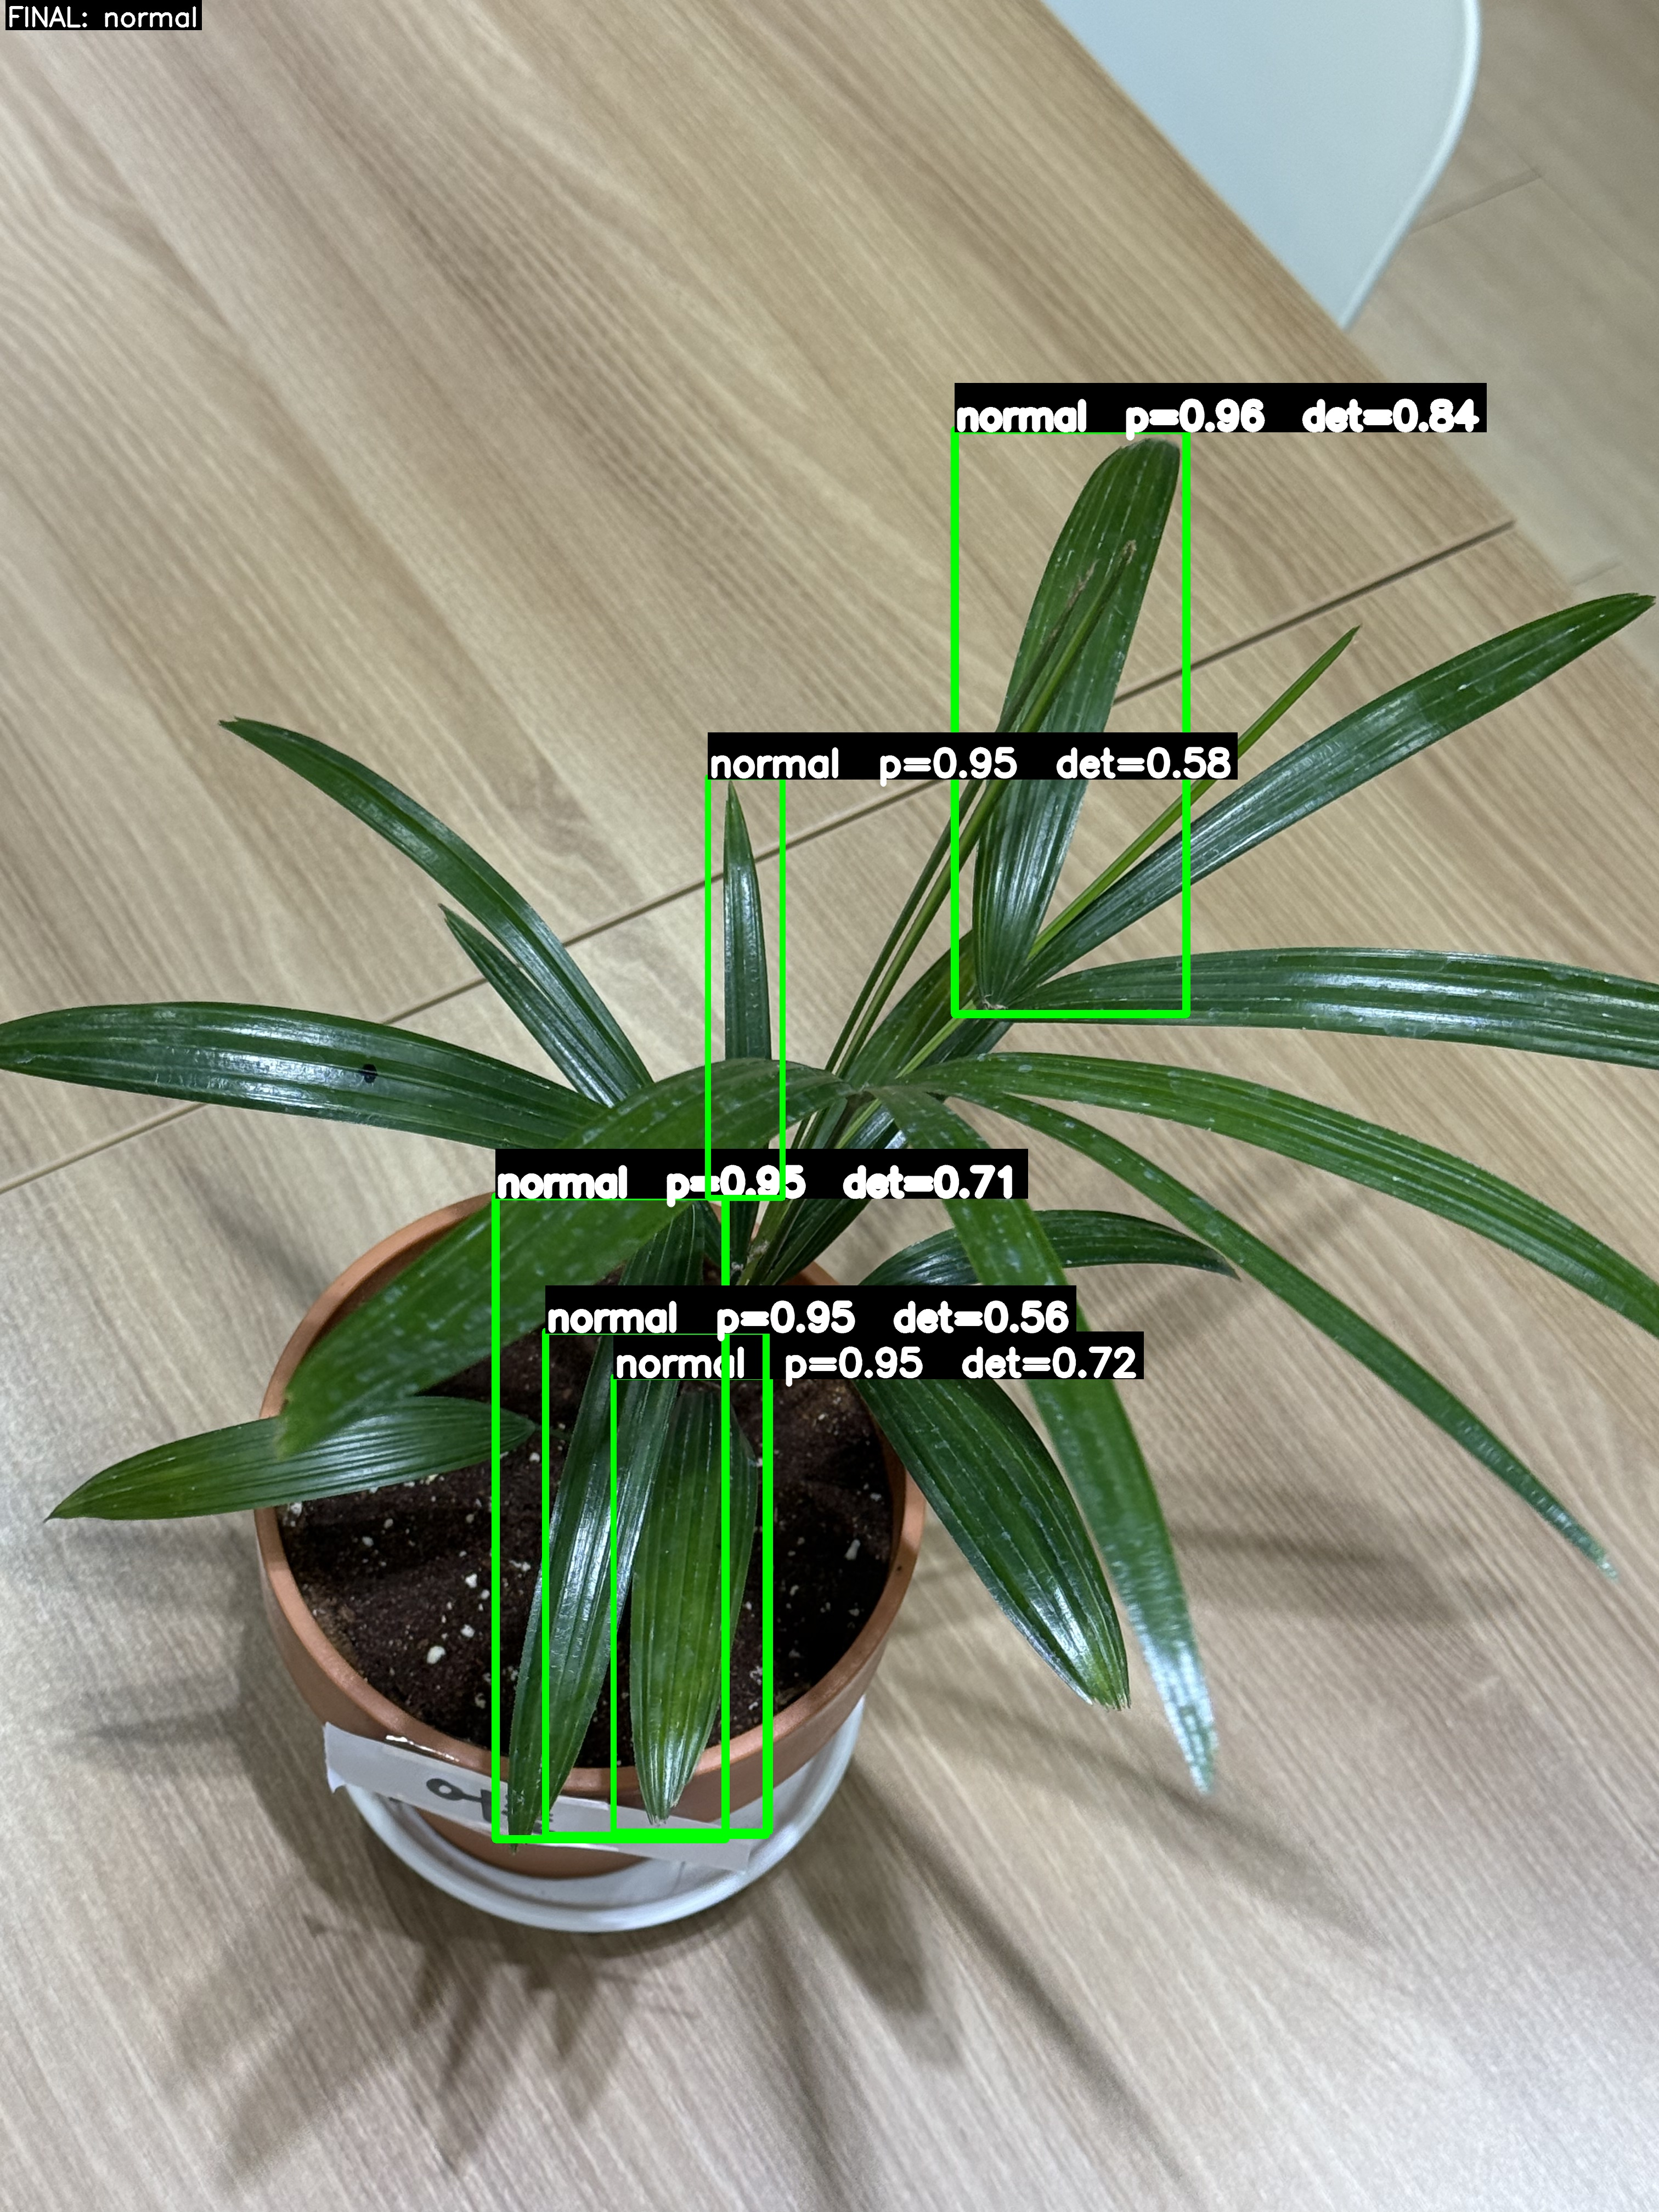

In [ ]:
# (선택) Colab에서 결과 이미지 바로 보기
from IPython.display import Image, display
display(Image("result_vis.jpg"))

In [ ]:
# p는 분류 모델의 확신도
# det는 YOLO가 “이게 잎이다”라고 생각하는 확신도